In [ ]:
from oso_airfoils.core.xfoil_wrapper import run as run_xfoil
from oso_airfoils.core.neuralfoil_wrapper import run as run_neuralfoil





alpha: [0. 1. 2. 3. 4. 5.]
cl:    [-1.11022302e-16  1.03048360e-01  2.07154040e-01  3.11690137e-01
  4.16828366e-01  5.22082918e-01]
cd:    [0.0044956  0.00457576 0.00479242 0.00502432 0.00526669 0.00555744]
cpmin: [-0.23531576 -0.40584517 -0.71739629 -1.09713086 -1.5171026  -1.88327845]
cp_data[0] x[:4]: [np.float64(0.984375), np.float64(0.953125), np.float64(0.921875), np.float64(0.890625)]
cp_data[0] cp[:4]: [np.float64(0.14585108781150136), np.float64(0.07659059310667504), np.float64(0.041373529348697424), np.float64(0.014003038912612786)]
bl_data[0] Ue/Vinf[:4]: [np.float64(0.9242017702798987), np.float64(0.960941937316363), np.float64(0.9790947199588519), np.float64(0.992973796777834)]
bl_data[0] Theta[:4]: [np.float64(0.001432821722379148), np.float64(0.0012158664246600624), np.float64(0.0011002483034183905), np.float64(0.0010092588404423824)]
bl_data[0] H[:4]: [np.float64(1.4374150711822637), np.float64(1.3979606039120516), np.float64(1.3863531750508316), np.float64(1.381658444

                   XFoil  NeuralFoil
CL                1.5115      1.5159
CD               0.00602     0.00621
CM               -0.2038     -0.2050
Xtr top           0.4005      0.3931
Xtr bot           0.4840      0.4914


Text(0.5, 1.01, '$\\alpha = 5.5°,\\ Re = 1e+07,\\ N_{cr} = 9.0$')

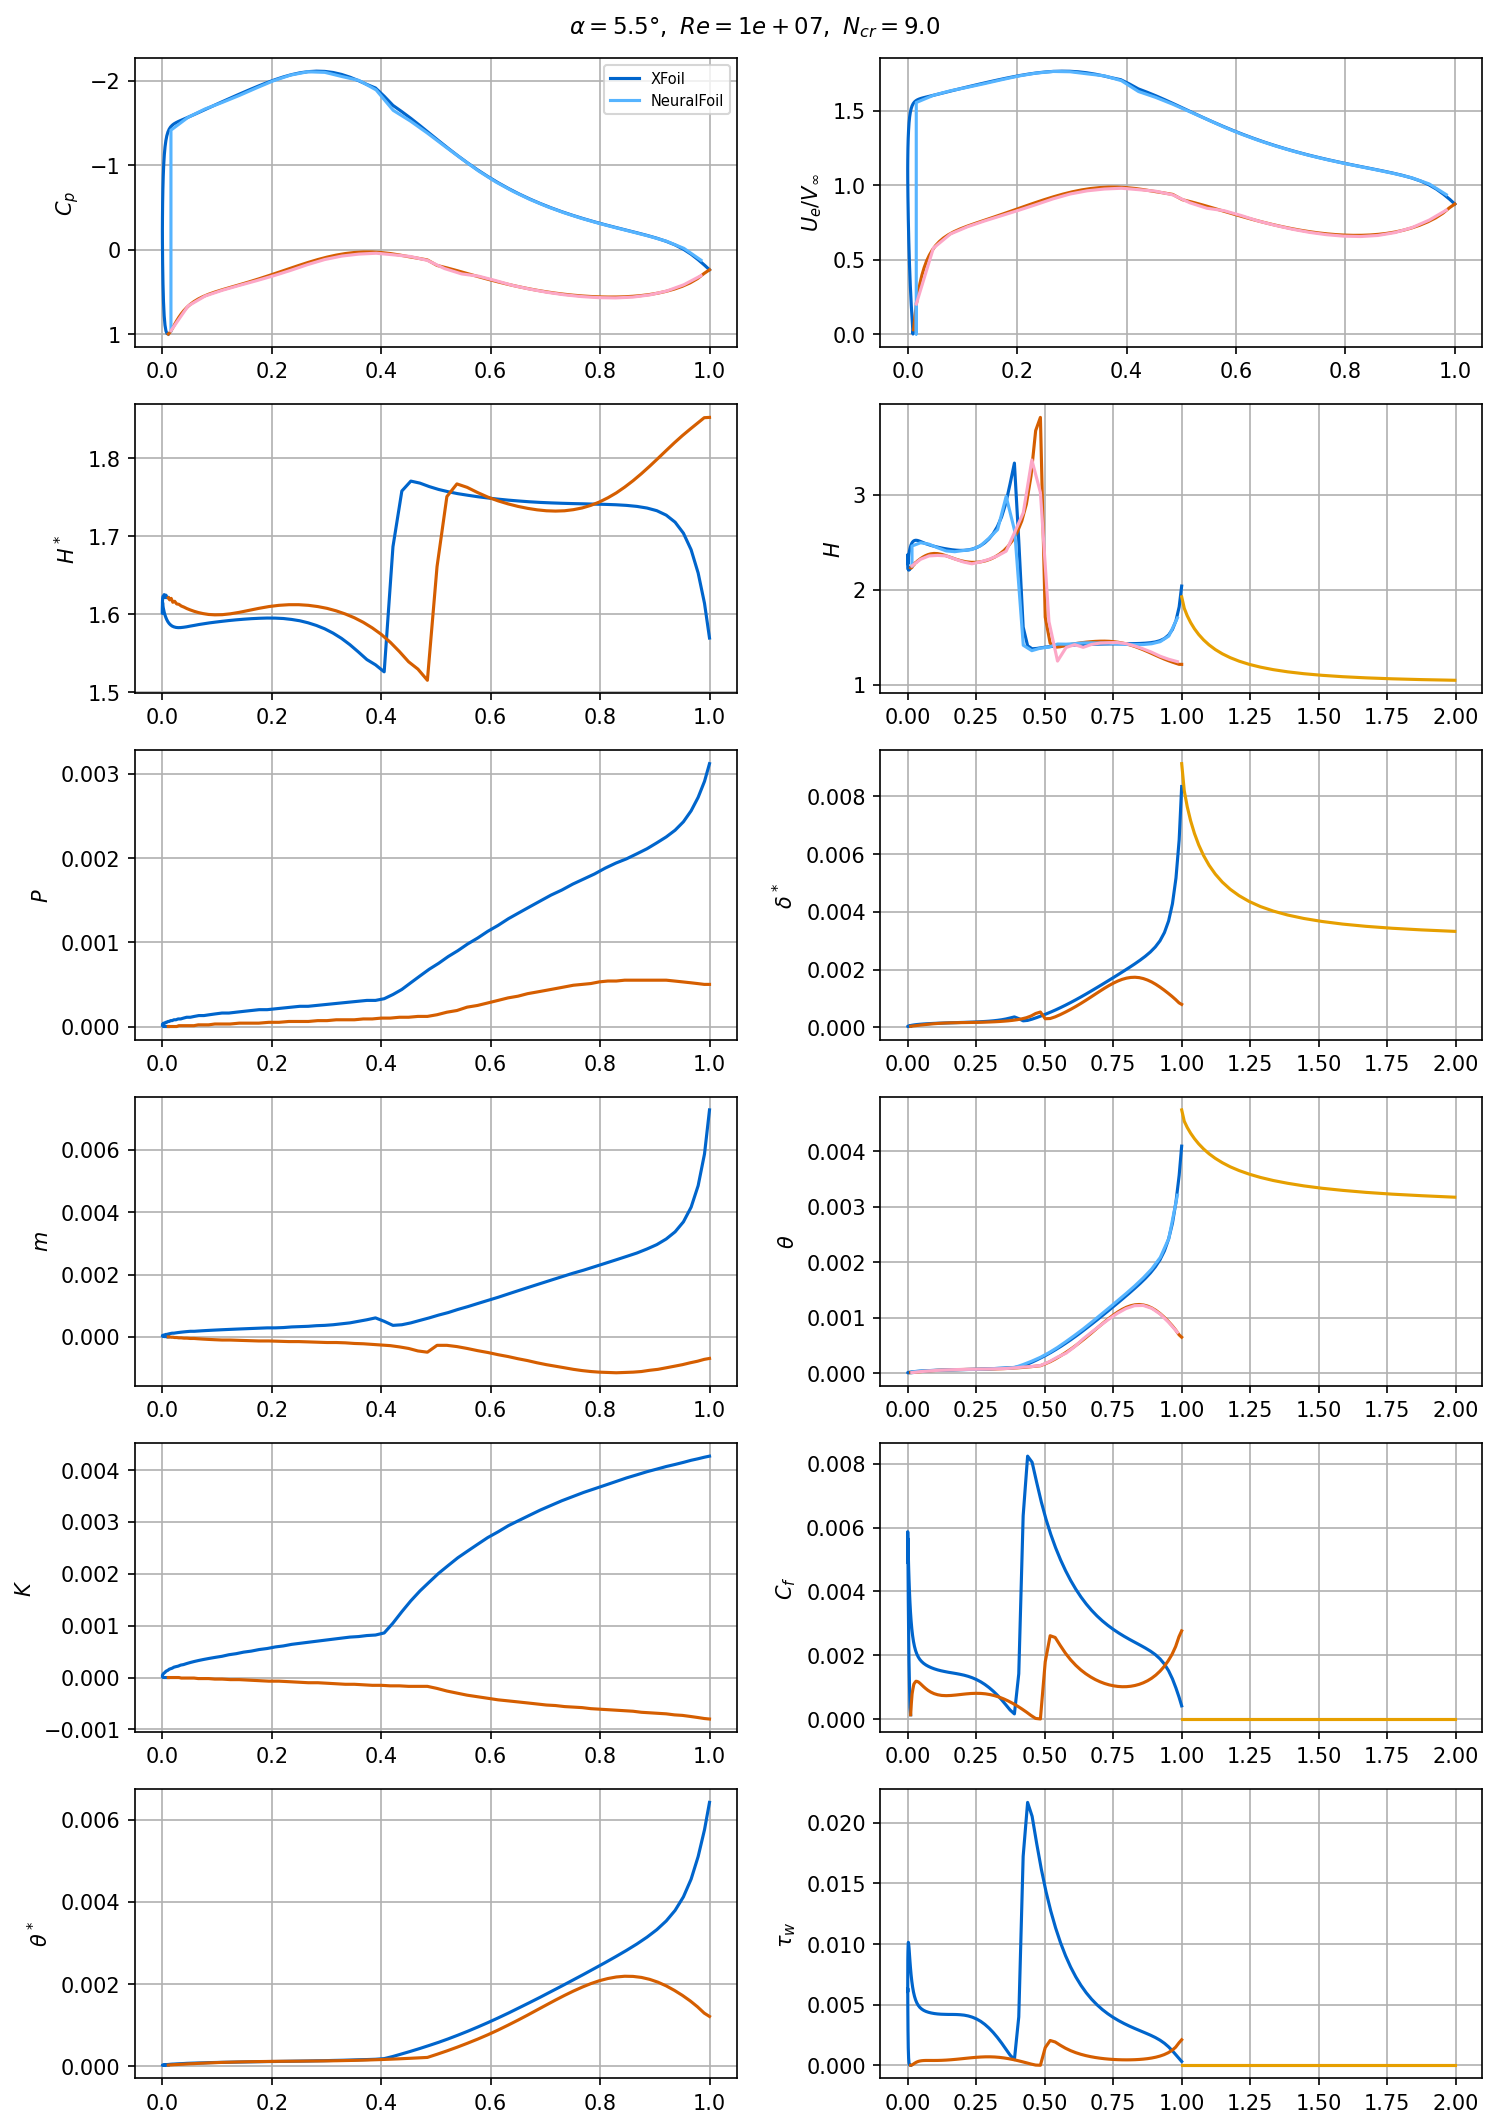

In [23]:
import sys, os
sys.path.insert(0, os.path.join(os.path.dirname(''), 'oso_airfoils', 'core'))

import numpy as np
import matplotlib.pyplot as plt

from oso_airfoils.core.xfoil_wrapper import run as run_xfoil
from oso_airfoils.core.neuralfoil_wrapper import run as run_neuralfoil
from oso_airfoils.core.boundary_layer_plot import boundary_layer_plot

# ── Shared inputs ──────────────────────────────────────────────────────────────
# uw    = [0.2, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.2]
# lw    = [-0.2] * 8

from oso_airfoils.airfoils import get_geometry
afl = get_geometry('oso-2025-wt2-t21')
uw = afl.upperCoefficients.magnitude
lw = afl.lowerCoefficients.magnitude
# print(uw)
# print(lw)

ALPHA = 5.5
RE    = 1e7
N_CR  = 9.0

# ── Run both solvers ───────────────────────────────────────────────────────────
res_xf = run_xfoil(
    'alpha', uw, lw,
    val=ALPHA, Re=RE, N_crit=N_CR,
    save_boundary_layer_data=True,
)

res_nf = run_neuralfoil(
    'alpha', uw, lw,
    val=ALPHA, Re=RE, N_crit=N_CR,
    model='xxxlarge',
)

# ── Pack into boundary_layer_plot data dicts ───────────────────────────────────
def _pack(res):
    return {
        'cp_data': res['cp_data'],
        'bl_data': res['bl_data'],
        're':      res['Re'],
        'alpha':   float(res['alpha']),
        'cl':      float(res['cl']),
        'cd':      float(res['cd']),
        'cm':      float(res['cm']),
        'n_crit':  res['N_crit'],
        'xtr_u':   float(res['xtr_top']),
        'xtr_l':   float(res['xtr_bot']),
    }

xf_data = _pack(res_xf)
nf_data = _pack(res_nf)

# ── Print quick comparison ─────────────────────────────────────────────────────
print(f"{'':12s}  {'XFoil':>10s}  {'NeuralFoil':>10s}")
print(f"{'CL':12s}  {res_xf['cl']:>10.4f}  {res_nf['cl']:>10.4f}")
print(f"{'CD':12s}  {res_xf['cd']:>10.5f}  {res_nf['cd']:>10.5f}")
print(f"{'CM':12s}  {res_xf['cm']:>10.4f}  {res_nf['cm']:>10.4f}")
print(f"{'Xtr top':12s}  {res_xf['xtr_top']:>10.4f}  {res_nf['xtr_top']:>10.4f}")
print(f"{'Xtr bot':12s}  {res_xf['xtr_bot']:>10.4f}  {res_nf['xtr_bot']:>10.4f}")

# ── Full multi-panel comparison ────────────────────────────────────────────────
fig = boundary_layer_plot(
    [xf_data, nf_data],
    parameter=None,
    dataIndicies=['XFoil', 'NeuralFoil'],
)
plt.suptitle(
    r'$\alpha = %.1f°,\ Re = %.0e,\ N_{cr} = %.1f$' % (ALPHA, RE, N_CR),
    y=1.01, fontsize=11,
)
